In [1]:
import cv2, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
from transformers import pipeline

In [2]:
true_counts = {
    "img_1.jpeg": 68, "img_2.jpeg": 23, "img_3.jpeg": 80,
    "img_4.jpg": 16,  "img_5.jpg": 60,
}   # approximate, used only for comparison

corners = {   # TL, TR, BR, BL as [x, y]
    "img_1.jpeg": [[0, 200], [400, 225], [360, 447], [25, 447]],
    "img_2.jpeg": [[0, 200], [400, 220], [330, 430], [25, 425]],
    "img_3.jpeg": [[50, 50], [380, 50], [335, 375], [110, 375]],
    "img_4.jpg":  [[0, 325], [447, 325], [447, 440], [10, 440]],
    "img_5.jpg":  [[0, 25], [275, 5], [275, 447], [0, 410]],
}

COL_FRACS = {
    "img_3.jpeg": [0, 0.247, 0.506, 0.765, 1.0],
    # "img_4.jpg": [0, 0.33, 0.66, 1.0],   # add the others after checking the rectified images
}

SCALE = 3   # upscale factor for the rectified image

In [3]:
def show(img_bgr, title="", figsize=(9, 9)):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title); plt.axis("off"); plt.show()

def get_size(path):
    tl, tr, br, bl = [np.array(p, dtype=float) for p in corners[path]]
    w = (np.linalg.norm(tr - tl) + np.linalg.norm(br - bl)) / 2
    h = (np.linalg.norm(bl - tl) + np.linalg.norm(br - tr)) / 2
    return int(w * SCALE), int(h * SCALE)

def rectify(path):
    w, h = get_size(path)
    src = np.float32(corners[path])
    dst = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    return cv2.warpPerspective(cv2.imread(path), cv2.getPerspectiveTransform(src, dst), (w, h))

def draw_dots_xy(path, centers, save=True):
    """centers are (x, y) in rectified coordinates; they get mapped back onto the original photo."""
    w, h = get_size(path)
    img = cv2.imread(path)
    src = np.float32(corners[path])
    dst = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    Minv = cv2.getPerspectiveTransform(dst, src)
    if len(centers):
        pts = cv2.perspectiveTransform(np.float32([[c] for c in centers]), Minv).reshape(-1, 2)
    else:
        pts = []
    order = sorted(range(len(pts)), key=lambda i: (round(pts[i][0] / 60), pts[i][1]))
    for n, i in enumerate(order, 1):
        x, y = pts[i]
        cv2.circle(img, (int(x), int(y)), 3, (0, 255, 0), -1)
        cv2.putText(img, str(n), (int(x) + 4, int(y) + 3),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.3, (0, 0, 255), 1)
    cv2.putText(img, f"Count: {len(centers)}", (10, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)
    if save:
        cv2.imwrite("marked_" + path, img)
    show(img, f"{path}: {len(centers)} planks")

In [5]:
device = 0 if torch.cuda.is_available() else -1
print("GPU" if device == 0 else "CPU (slow)")
sam = pipeline("mask-generation", model="facebook/sam-vit-base", device=device)
# if holes get missed, try "facebook/sam-vit-large"

CPU (slow)


config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

In [6]:
def _starts(n, t, stride):
    if n <= t:
        return [0]
    s = list(range(0, n - t + 1, stride))
    if s[-1] + t < n:
        s.append(n - t)
    return s

def _dedupe_pts(pts, min_dist):
    kept = []
    for p in pts:
        if all(np.hypot(p[0] - q[0], p[1] - q[1]) > min_dist for q in kept):
            kept.append(p)
    return kept

HOLES = {}   # cache: path -> list of (x, y) in rectified pixels

def detect_holes_sam(path, tile=384, overlap=64, min_d=5, max_d=None,
                     min_contrast=0.15, points=48):
    flat = rectify(path)
    H, W = flat.shape[:2]
    max_d = max_d or 0.04 * W                      # biggest allowed hole diameter, in rectified px
    rgb = cv2.cvtColor(flat, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY).astype(float) / 255
    stride = tile - overlap
    found = []

    for y in _starts(H, tile, stride):
        for x in _starts(W, tile, stride):
            tw, th = min(tile, W - x), min(tile, H - y)
            out = sam(Image.fromarray(rgb[y:y + th, x:x + tw]),
                      points_per_batch=64, points_per_crop=points)
            g = gray[y:y + th, x:x + tw]
            for m in out["masks"]:
                m = np.asarray(m).astype(bool)
                ys, xs = np.nonzero(m)
                if len(xs) == 0:
                    continue
                x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
                if x0 == 0 or y0 == 0 or x1 == tw - 1 or y1 == th - 1:
                    continue                       # cut off by the tile edge; the overlap covers it
                w, h = x1 - x0 + 1, y1 - y0 + 1
                if not (min_d <= w <= max_d and min_d <= h <= max_d):
                    continue
                if not (0.6 <= w / h <= 1.7) or m.sum() / (w * h) < 0.55:
                    continue                       # must be roundish and filled
                k = int(max(w, h)) | 1
                ring = cv2.dilate(m.astype(np.uint8), np.ones((k, k), np.uint8)).astype(bool) & ~m
                if g[ring].mean() - g[m].mean() < min_contrast:
                    continue                       # must be darker than its surroundings
                found.append((xs.mean() + x, ys.mean() + y))

    return _dedupe_pts(found, min_d)               # same hole seen in two overlapping tiles

def get_holes(path, force=False, **kw):
    if force or path not in HOLES:
        HOLES[path] = detect_holes_sam(path, **kw)
    return HOLES[path]

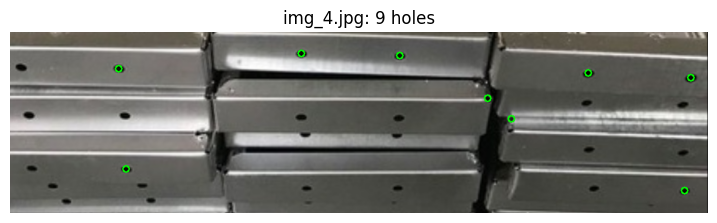

In [7]:
def show_holes(path, force=False, **kw):
    flat = rectify(path)
    holes = get_holes(path, force=force, **kw)
    ov = flat.copy()
    for x, y in holes:
        cv2.circle(ov, (int(x), int(y)), 6, (0, 255, 0), 2)
    for f in COL_FRACS.get(path, [])[1:-1]:
        cv2.line(ov, (int(f * flat.shape[1]), 0), (int(f * flat.shape[1]), flat.shape[0]), (0, 255, 255), 2)
    show(ov, f"{path}: {len(holes)} holes")

show_holes("img_4.jpg")

  column 1: 9 holes -> 6 planks (gap threshold 19.7)
img_4.jpg: 6 planks (hand count 16)


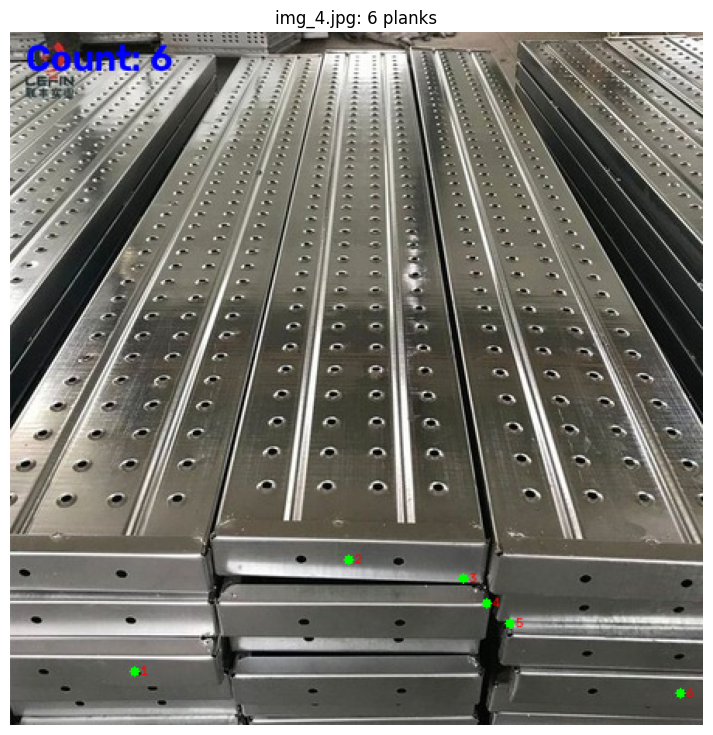

In [8]:
GAP_THR = {}   # optional per-image override in rectified px, e.g. {"img_4.jpg": 25}

def group_planks(holes, col_edges_px, gap_thr=None):
    centers = []
    for i in range(len(col_edges_px) - 1):
        x0, x1 = col_edges_px[i], col_edges_px[i + 1]
        pts = np.array(sorted([p for p in holes if x0 <= p[0] < x1], key=lambda p: p[1]))
        if len(pts) == 0:
            print(f"  column {i+1}: no holes"); continue
        gaps = np.diff(pts[:, 1])
        thr = gap_thr
        if thr is None:     # auto: half the typical jump between planks
            big = gaps[gaps > 0.3 * np.percentile(gaps, 90)] if len(gaps) else gaps
            thr = 0.5 * np.median(big) if len(big) else 1
        groups = np.split(pts, np.where(gaps > thr)[0] + 1)
        centers += [(g[:, 0].mean(), g[:, 1].mean()) for g in groups]
        print(f"  column {i+1}: {len(pts)} holes -> {len(groups)} planks (gap threshold {thr:.1f})")
    return centers

def count_by_holes(path, draw=True):
    w, _ = get_size(path)
    edges = [f * w for f in COL_FRACS.get(path, [0, 1])]
    centers = group_planks(get_holes(path), edges, GAP_THR.get(path))
    print(f"{path}: {len(centers)} planks (hand count {true_counts.get(path)})")
    if draw:
        draw_dots_xy(path, centers)
    return centers

centers = count_by_holes("img_4.jpg")